# **CS 5361/6361 Machine Learning**

**CNNs to classify MNIST and CIFAR-10**

**Author:** Olac Fuentes<br>
Computer Science Department<br>
University of Texas at El Paso<br>
**Last modified:** 4/28/2026<br>

### **Evaluation on the MNIST Dataset**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.losses import *
from tensorflow.keras.activations import *
from tensorflow.keras.regularizers import *
from keras.utils import plot_model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
import time

def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()

Read data

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X_train = np.float32(np.expand_dims(X_train, -1)/255.0)
X_test = np.float32(np.expand_dims(X_test, -1)/255.0)
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28, 1)
(60000, 10)
(10000, 28, 28, 1)
(10000, 10)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
600/600 - 6s - 9ms/step - accuracy: 0.9389 - loss: 0.2034 - val_accuracy: 0.9785 - val_loss: 0.0682
Epoch 2/40
600/600 - 3s - 5ms/step - accuracy: 0.9826 - loss: 0.0566 - val_accuracy: 0.9816 - val_loss: 0.0566
Epoch 3/40
600/600 - 3s - 4ms/step - accuracy: 0.9879 - loss: 0.0401 - val_accuracy: 0.9883 - val_loss: 0.0330
Epoch 4/40
600/600 - 3s - 4ms/step - accuracy: 0.9901 - loss: 0.0317 - val_accuracy: 0.9880 - val_loss: 0.0355
Epoch 5/40
600/600 - 3s - 4ms/step - accuracy: 0.9922 - loss: 0.0245 - val_accuracy: 0.9905 - val_loss: 0.0312
Epoch 6/40
600/600 - 5s - 9ms/step - accuracy: 0.9937 - loss: 0.0193 - val_accuracy: 0.9901 - val_loss: 0.0298
Epoch 7/40
600/600 - 5s - 8ms/step - accuracy: 0.9951 - loss: 0.0155 - val_accuracy: 0.9903 - val_loss: 0.0323
Epoch 8/40
600/600 - 3s - 4ms/step - accuracy: 0.9956 - loss: 0.0134 - val_accuracy: 0.9900 - val_loss: 0.0307
Epoch 9/40
600/600 - 3s - 5ms/step - accuracy: 0.9959 - loss: 0.0116 - val_accuracy: 0.9908 - val_loss: 0.0317
E

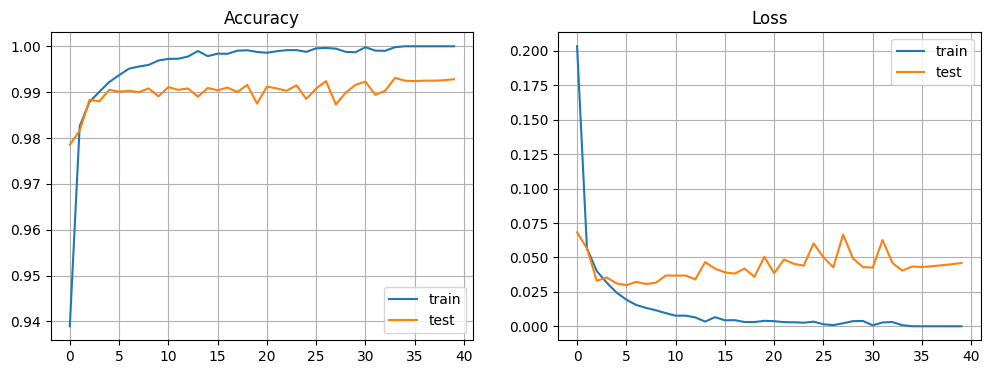

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 127.8531 secs
Accuracy = 0.9931


In [ ]:
def cnn_model(input_shape, conv_units, dense_units):
  model = tf.keras.models.Sequential()
  model.add(Input(shape=input_shape))
  for c in conv_units:
    model.add(Conv2D(c, kernel_size=(3, 3),  padding='same', activation="relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
  model.add(Flatten())
  for d in dense_units:
    model.add(Dense(d, activation='relu'))
  model.add(Dense(10, activation='softmax'))
  return model

model = cnn_model(input_shape=(28,28,1), conv_units = [32,64],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    X_train, y_train,
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

### **Evaluation on the CIFAR-10 dataset**

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
X_train = np.float32(X_train/255.0)
X_test = np.float32(X_test/255.0)
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
(50000, 32, 32, 3)
(50000, 10)
(10000, 32, 32, 3)
(10000, 10)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
500/500 - 6s - 12ms/step - accuracy: 0.4376 - loss: 1.5707 - val_accuracy: 0.5268 - val_loss: 1.3256
Epoch 2/40
500/500 - 3s - 6ms/step - accuracy: 0.5848 - loss: 1.1896 - val_accuracy: 0.6079 - val_loss: 1.1052
Epoch 3/40
500/500 - 3s - 6ms/step - accuracy: 0.6345 - loss: 1.0468 - val_accuracy: 0.6403 - val_loss: 1.0286
Epoch 4/40
500/500 - 3s - 5ms/step - accuracy: 0.6679 - loss: 0.9582 - val_accuracy: 0.6597 - val_loss: 0.9741
Epoch 5/40
500/500 - 5s - 10ms/step - accuracy: 0.6921 - loss: 0.8906 - val_accuracy: 0.6631 - val_loss: 0.9794
Epoch 6/40
500/500 - 3s - 6ms/step - accuracy: 0.7080 - loss: 0.8440 - val_accuracy: 0.6952 - val_loss: 0.8815
Epoch 7/40
500/500 - 3s - 5ms/step - accuracy: 0.7216 - loss: 0.8046 - val_accuracy: 0.6952 - val_loss: 0.8905
Epoch 8/40
500/500 - 3s - 5ms/step - accuracy: 0.7353 - loss: 0.7638 - val_accuracy: 0.7033 - val_loss: 0.8723
Epoch 9/40
500/500 - 3s - 5ms/step - accuracy: 0.7469 - loss: 0.7296 - val_accuracy: 0.7079 - val_loss: 0.8662

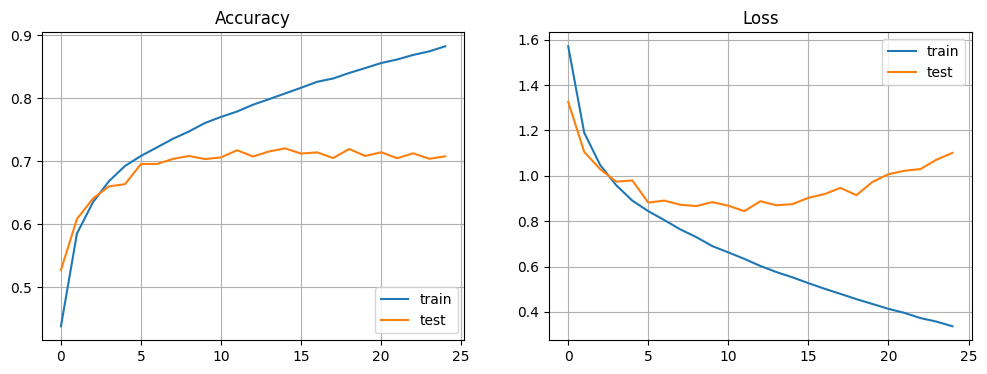

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 77.0604 secs
Accuracy = 0.7200


In [ ]:
model = cnn_model(input_shape=(32,32,3), conv_units = [32,64],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    X_train, y_train,
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 96)       │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        98,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,802 (678.91 KB)

 Trainable params: 173,802 (678.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
500/500 - 8s - 15ms/step - accuracy: 0.4319 - loss: 1.5602 - val_accuracy: 0.5332 - val_loss: 1.2969
Epoch 2/40
500/500 - 3s - 6ms/step - accuracy: 0.5848 - loss: 1.1670 - val_accuracy: 0.6160 - val_loss: 1.0935
Epoch 3/40
500/500 - 3s - 6ms/step - accuracy: 0.6564 - loss: 0.9832 - val_accuracy: 0.6773 - val_loss: 0.9378
Epoch 4/40
500/500 - 4s - 7ms/step - accuracy: 0.6959 - loss: 0.8761 - val_accuracy: 0.6667 - val_loss: 0.9581
Epoch 5/40
500/500 - 3s - 6ms/step - accuracy: 0.7253 - loss: 0.7890 - val_accuracy: 0.6898 - val_loss: 0.8946
Epoch 6/40
500/500 - 3s - 6ms/step - accuracy: 0.7474 - loss: 0.7272 - val_accuracy: 0.7193 - val_loss: 0.8075
Epoch 7/40
500/500 - 3s - 6ms/step - accuracy: 0.7686 - loss: 0.6715 - val_accuracy: 0.7218 - val_loss: 0.8121
Epoch 8/40
500/500 - 3s - 7ms/step - accuracy: 0.7832 - loss: 0.6249 - val_accuracy: 0.7212 - val_loss: 0.8122
Epoch 9/40
500/500 - 3s - 6ms/step - accuracy: 0.7997 - loss: 0.5767 - val_accuracy: 0.7338 - val_loss: 0.7947


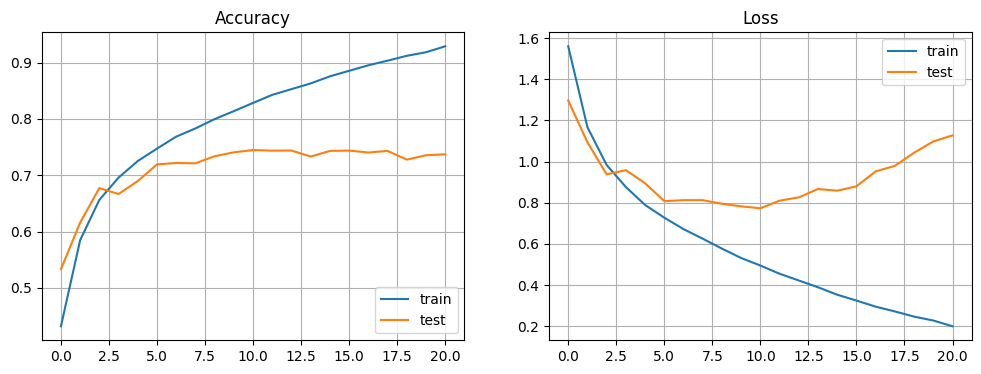

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 73.8527 secs
Accuracy = 0.7448


In [ ]:
model = cnn_model(input_shape=(32,32,3), conv_units = [32,64,96],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    X_train, y_train,
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

Adding back-to-back convolutional layers insdead of single layer

In [ ]:
def cnn_model(input_shape, conv_units, dense_units):
  model = tf.keras.models.Sequential()
  model.add(Input(shape=input_shape))
  for c in conv_units:
    model.add(Conv2D(c, kernel_size=(3, 3),  padding='same', activation="relu"))
    model.add(Conv2D(c, kernel_size=(3, 3),  padding='same', activation="relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
  model.add(Flatten())
  for d in dense_units:
    model.add(Dense(d, activation='relu'))
  model.add(Dense(10, activation='softmax'))
  return model

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_54 (Conv2D)              │ (None, 32, 32, 48)     │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 32, 32, 48)     │        20,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 16, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 16, 16, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 8, 8, 96)       │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 8, 8, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │        98,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 324,218 (1.24 MB)

 Trainable params: 324,218 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
500/500 - 12s - 25ms/step - accuracy: 0.4394 - loss: 1.5346 - val_accuracy: 0.5722 - val_loss: 1.1963
Epoch 2/40
500/500 - 7s - 13ms/step - accuracy: 0.6318 - loss: 1.0377 - val_accuracy: 0.6721 - val_loss: 0.9260
Epoch 3/40
500/500 - 7s - 13ms/step - accuracy: 0.7085 - loss: 0.8296 - val_accuracy: 0.7224 - val_loss: 0.7865
Epoch 4/40
500/500 - 7s - 13ms/step - accuracy: 0.7567 - loss: 0.6948 - val_accuracy: 0.7529 - val_loss: 0.7149
Epoch 5/40
500/500 - 6s - 13ms/step - accuracy: 0.7919 - loss: 0.5955 - val_accuracy: 0.7620 - val_loss: 0.6886
Epoch 6/40
500/500 - 7s - 13ms/step - accuracy: 0.8184 - loss: 0.5178 - val_accuracy: 0.7587 - val_loss: 0.7098
Epoch 7/40
500/500 - 6s - 12ms/step - accuracy: 0.8417 - loss: 0.4469 - val_accuracy: 0.7737 - val_loss: 0.6698
Epoch 8/40
500/500 - 6s - 13ms/step - accuracy: 0.8664 - loss: 0.3816 - val_accuracy: 0.7779 - val_loss: 0.6956
Epoch 9/40
500/500 - 6s - 12ms/step - accuracy: 0.8861 - loss: 0.3214 - val_accuracy: 0.7756 - val_loss

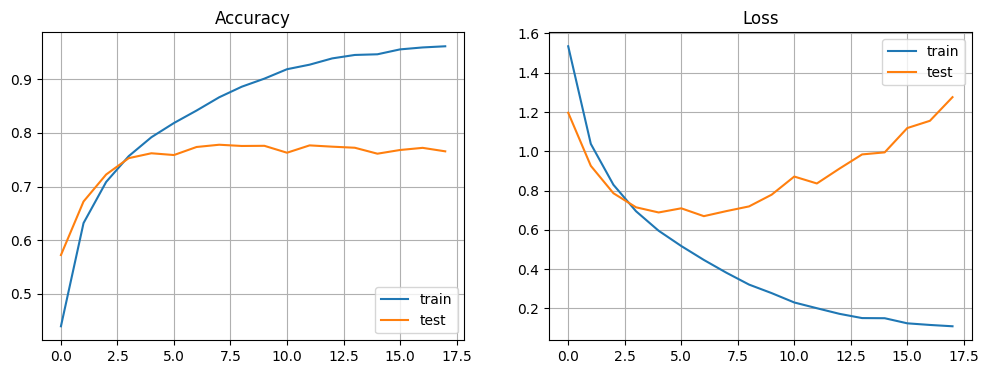

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 122.7018 secs
Accuracy = 0.7779


In [ ]:
model = cnn_model(input_shape=(32,32,3), conv_units = [48,64,96],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    X_train, y_train,
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_66 (Conv2D)              │ (None, 32, 32, 48)     │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_67 (Conv2D)              │ (None, 32, 32, 48)     │        20,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 16, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_68 (Conv2D)              │ (None, 16, 16, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_69 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 8, 8, 96)       │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 8, 8, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │        98,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 324,218 (1.24 MB)

 Trainable params: 324,218 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1000/1000 - 18s - 18ms/step - accuracy: 0.5250 - loss: 1.3069 - val_accuracy: 0.6491 - val_loss: 1.0060
Epoch 2/40
1000/1000 - 12s - 12ms/step - accuracy: 0.7184 - loss: 0.8007 - val_accuracy: 0.7407 - val_loss: 0.7482
Epoch 3/40
1000/1000 - 12s - 12ms/step - accuracy: 0.7816 - loss: 0.6277 - val_accuracy: 0.7858 - val_loss: 0.6451
Epoch 4/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8177 - loss: 0.5270 - val_accuracy: 0.7962 - val_loss: 0.6128
Epoch 5/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8404 - loss: 0.4589 - val_accuracy: 0.8024 - val_loss: 0.5941
Epoch 6/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8607 - loss: 0.3990 - val_accuracy: 0.8179 - val_loss: 0.5692
Epoch 7/40
1000/1000 - 14s - 14ms/step - accuracy: 0.8776 - loss: 0.3496 - val_accuracy: 0.8199 - val_loss: 0.5574
Epoch 8/40
1000/1000 - 22s - 22ms/step - accuracy: 0.8910 - loss: 0.3084 - val_accuracy: 0.8120 - val_loss: 0.6199
Epoch 9/40
1000/1000 - 14s - 14ms/step - accuracy: 0.9031 - loss: 0.2727 - val_a

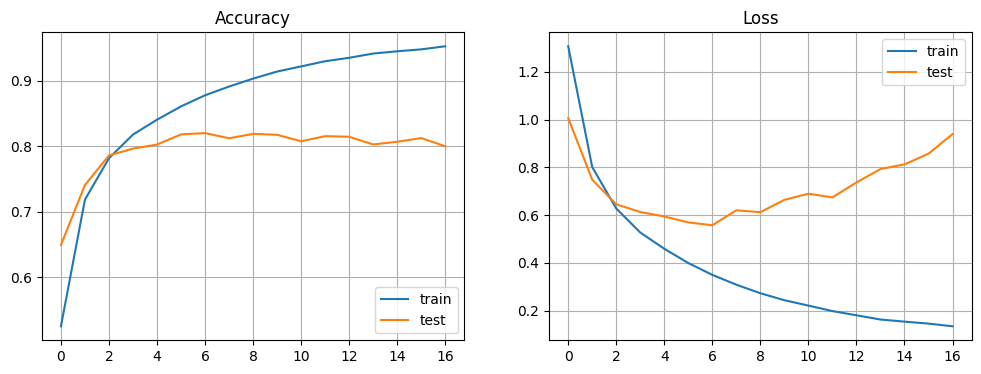

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Elapsed time training= 239.1034 secs
Accuracy = 0.8199


In [ ]:
model = cnn_model(input_shape=(32,32,3), conv_units = [48,64,96],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    np.append(X_train,X_train[:,:,::-1],axis=0), np.append(y_train,y_train,axis=0),
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

Combining predictions for original and mirrored data

In [ ]:
pred1 = model.predict(X_test)
pred2 = model.predict(X_test[:,:,::-1])
print('Accuracy on orignal test set = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred1,axis=1))))
print('Accuracy on mirrored test set = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred2,axis=1))))
print('Accuracy combining predictions= {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred1+pred2,axis=1))))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 239.1034 secs
Accuracy on orignal test set = 0.8199
Accuracy on mirrored test set = 0.8133
Accuracy combining predictions= 0.8325


In [ ]:
def cnn_model(input_shape, conv_units, dense_units):
  model = tf.keras.models.Sequential()
  model.add(Input(shape=input_shape))
  for c in conv_units:
    model.add(Conv2D(c, kernel_size=(3, 3),  padding='same', activation="relu"))
    model.add(Conv2D(c, kernel_size=(3, 3),  padding='same', activation="relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(.2))
  model.add(Flatten())
  for d in dense_units:
    model.add(Dense(d, activation='relu'))
    model.add(Dropout(.2))
  model.add(Dense(10, activation='softmax'))
  return model

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_78 (Conv2D)              │ (None, 32, 32, 48)     │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_79 (Conv2D)              │ (None, 32, 32, 48)     │        20,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_44 (MaxPooling2D) │ (None, 16, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_80 (Conv2D)              │ (None, 16, 16, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_81 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_82 (Conv2D)              │ (None, 8, 8, 96)       │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_83 (Conv2D)              │ (None, 8, 8, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │        98,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 324,218 (1.24 MB)

 Trainable params: 324,218 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1000/1000 - 21s - 21ms/step - accuracy: 0.4580 - loss: 1.4804 - val_accuracy: 0.6317 - val_loss: 1.0453
Epoch 2/40
1000/1000 - 13s - 13ms/step - accuracy: 0.6502 - loss: 0.9927 - val_accuracy: 0.7198 - val_loss: 0.7973
Epoch 3/40
1000/1000 - 12s - 12ms/step - accuracy: 0.7151 - loss: 0.8153 - val_accuracy: 0.7518 - val_loss: 0.7176
Epoch 4/40
1000/1000 - 14s - 14ms/step - accuracy: 0.7513 - loss: 0.7124 - val_accuracy: 0.7754 - val_loss: 0.6399
Epoch 5/40
1000/1000 - 19s - 19ms/step - accuracy: 0.7716 - loss: 0.6564 - val_accuracy: 0.7858 - val_loss: 0.6206
Epoch 6/40
1000/1000 - 12s - 12ms/step - accuracy: 0.7902 - loss: 0.6074 - val_accuracy: 0.8122 - val_loss: 0.5616
Epoch 7/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8041 - loss: 0.5664 - val_accuracy: 0.8135 - val_loss: 0.5518
Epoch 8/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8113 - loss: 0.5485 - val_accuracy: 0.8120 - val_loss: 0.5576
Epoch 9/40
1000/1000 - 12s - 12ms/step - accuracy: 0.8198 - loss: 0.5208 - val_a

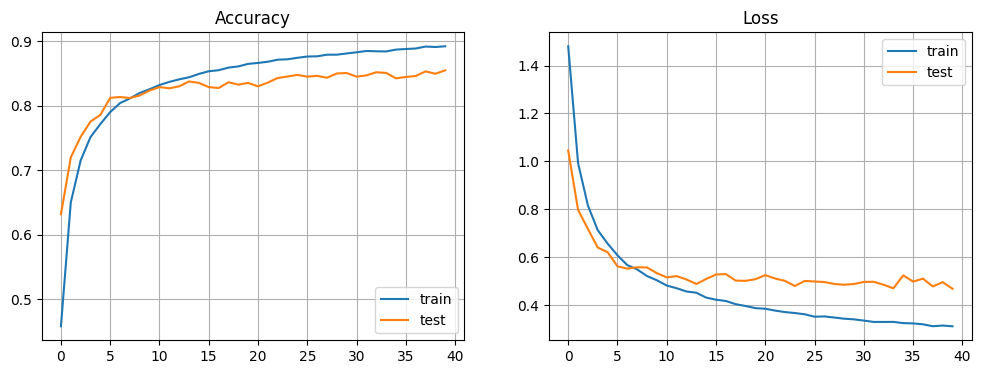

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 529.8898 secs
Accuracy = 0.8549


In [ ]:
model = cnn_model(input_shape=(32,32,3), conv_units = [48,64,96],dense_units = [64])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(),loss="CategoricalCrossentropy", metrics=["accuracy"])

earlystopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

start_train = time.time()
history = model.fit(
    np.append(X_train,X_train[:,:,::-1],axis=0), np.append(y_train,y_train,axis=0),
    epochs = 40,
    batch_size = 100,
    verbose = 2,
    validation_data=(X_test, y_test),
    callbacks = [earlystopping]
)
end_train = time.time()
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
plot_results(history)
pred = model.predict(X_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
print('Accuracy = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred,axis=1))))

In [ ]:
pred1 = model.predict(X_test)
pred2 = model.predict(X_test[:,:,::-1])
print('Accuracy on orignal test set = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred1,axis=1))))
print('Accuracy on mirrored test set = {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred2,axis=1))))
print('Accuracy combining predictions= {:.4f}'.format(accuracy_score(np.argmax(y_test,axis=1),np.argmax(pred1+pred2,axis=1))))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy on orignal test set = 0.8549
Accuracy on mirrored test set = 0.8556
Accuracy combining predictions= 0.8698
